In [ ]:
# Install required libraries
!pip install transformers torch --quiet

In [ ]:
# Import BERT tokenizer and model
from transformers import BertTokenizer, BertModel
import torch
import numpy as np
from tqdm import tqdm

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
bert_model = BertModel.from_pretrained('bert-base-uncased')

In [ ]:
# Define a function to get BERT embeddings
def get_bert_embedding(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, padding=True, max_length=512)
    with torch.no_grad():
        outputs = bert_model(**inputs)
    return outputs.last_hidden_state[:, 0, :].squeeze().numpy()  # CLS token embedding

In [ ]:
# Generate embeddings for all text data
X_bert = np.array([get_bert_embedding(text) for text in tqdm(df['text'])])
# Replace original feature matrix X with BERT embeddings
X = X_bert

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df_fake = pd.read_csv("/content/drive/MyDrive/ML Project/Fake.csv", low_memory=False)
df_true = pd.read_csv("/content/drive/MyDrive/ML Project/True.csv", low_memory=False)

In [ ]:
df_fake.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23502 entries, 0 to 23501
Columns: 172 entries, title to Unnamed: 171
dtypes: object(172)
memory usage: 30.8+ MB


In [ ]:
df_true.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB


In [ ]:
print(df_fake.columns)
print(len(df_fake.columns))

Index(['title', 'text', 'subject', 'date', 'Unnamed: 4', 'Unnamed: 5',
       'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9',
       ...
       'Unnamed: 162', 'Unnamed: 163', 'Unnamed: 164', 'Unnamed: 165',
       'Unnamed: 166', 'Unnamed: 167', 'Unnamed: 168', 'Unnamed: 169',
       'Unnamed: 170', 'Unnamed: 171'],
      dtype='object', length=172)
172


In [ ]:
df_fake = df_fake.loc[:, ~df_fake.columns.str.contains('^Unnamed')]

In [ ]:
print(df_fake.columns)
print(len(df_fake.columns))

Index(['title', 'text', 'subject', 'date'], dtype='object')
4


In [ ]:
df_fake.head(10)

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"
5,Racist Alabama Cops Brutalize Black Boy While...,The number of cases of cops brutalizing and ki...,News,"December 25, 2017"
6,"Fresh Off The Golf Course, Trump Lashes Out A...",Donald Trump spent a good portion of his day a...,News,"December 23, 2017"
7,Trump Said Some INSANELY Racist Stuff Inside ...,In the wake of yet another court decision that...,News,"December 23, 2017"
8,Former CIA Director Slams Trump Over UN Bully...,Many people have raised the alarm regarding th...,News,"December 22, 2017"
9,WATCH: Brand-New Pro-Trump Ad Features So Muc...,Just when you might have thought we d get a br...,News,"December 21, 2017"


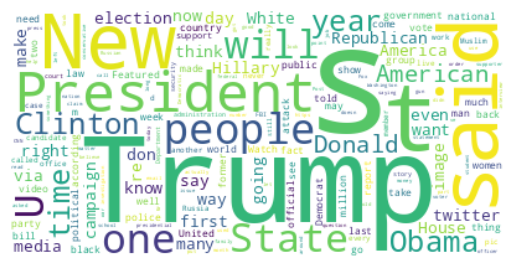

In [ ]:
word_cloud = WordCloud(collocations = False, background_color = 'white').generate(" ".join(df_fake['text']))

plt.imshow(word_cloud, interpolation='bilinear')
plt.axis("off")
plt.show()

In [ ]:

print(df_true.columns)
print(len(df_true.columns))

Index(['title', 'text', 'subject', 'date'], dtype='object')
4


In [ ]:
df_true.head(10)

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"
5,"White House, Congress prepare for talks on spe...","WEST PALM BEACH, Fla./WASHINGTON (Reuters) - T...",politicsNews,"December 29, 2017"
6,"Trump says Russia probe will be fair, but time...","WEST PALM BEACH, Fla (Reuters) - President Don...",politicsNews,"December 29, 2017"
7,Factbox: Trump on Twitter (Dec 29) - Approval ...,The following statements were posted to the ve...,politicsNews,"December 29, 2017"
8,Trump on Twitter (Dec 28) - Global Warming,The following statements were posted to the ve...,politicsNews,"December 29, 2017"
9,Alabama official to certify Senator-elect Jone...,WASHINGTON (Reuters) - Alabama Secretary of St...,politicsNews,"December 28, 2017"


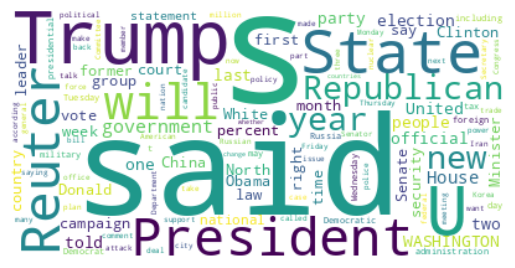

In [ ]:
word_cloud = WordCloud(collocations = False, background_color = 'white').generate(" ".join(df_true['text']))

plt.imshow(word_cloud, interpolation='bilinear')
plt.axis("off")
plt.show()

In [ ]:
df_fake["class"] = 0
df_true["class"] = 1

In [ ]:
df_fake.shape, df_true.shape

((23502, 5), (21417, 5))

In [ ]:
df_fake_manual_testing = df_fake.tail(10)
df_fake = df_fake.iloc[:-10]

df_true_manual_testing = df_true.tail(10)
df_true = df_true.iloc[:-10]

In [ ]:
df_fake.shape, df_true.shape

((23492, 5), (21407, 5))

In [ ]:
df_fake_manual_testing

,title,text,subject,date,class
23492,Seven Iranians freed in the prisoner swap have...,"21st Century Wire says This week, the historic...",Middle-east,"January 20, 2016",0
23493,#Hashtag Hell & The Fake Left,By Dady Chery and Gilbert MercierAll writers ...,Middle-east,"January 19, 2016",0
23494,Astroturfing: Journalist Reveals Brainwashing ...,Vic Bishop Waking TimesOur reality is carefull...,Middle-east,"January 19, 2016",0
23495,The New American Century: An Era of Fraud,Paul Craig RobertsIn the last years of the 20t...,Middle-east,"January 19, 2016",0
23496,Hillary Clinton: ‘Israel First’ (and no peace ...,Robert Fantina CounterpunchAlthough the United...,Middle-east,"January 18, 2016",0
23497,McPain: John McCain Furious That Iran Treated ...,21st Century Wire says As 21WIRE reported earl...,Middle-east,"January 16, 2016",0
23498,JUSTICE? Yahoo Settles E-mail Privacy Class-ac...,21st Century Wire says It s a familiar theme. ...,Middle-east,"January 16, 2016",0
23499,Sunnistan: US and Allied ‘Safe Zone’ Plan to T...,Patrick Henningsen 21st Century WireRemember ...,Middle-east,"January 15, 2016",0
23500,How to Blow $700 Million: Al Jazeera America F...,21st Century Wire says Al Jazeera America will...,Middle-east,"January 14, 2016",0
23501,10 U.S. Navy Sailors Held by Iranian Military ...,21st Century Wire says As 21WIRE predicted in ...,Middle-east,"January 12, 2016",0


In [ ]:
df_true_manual_testing

,title,text,subject,date,class
21407,"Mata Pires, owner of embattled Brazil builder ...","SAO PAULO (Reuters) - Cesar Mata Pires, the ow...",worldnews,"August 22, 2017",1
21408,"U.S., North Korea clash at U.N. forum over nuc...",GENEVA (Reuters) - North Korea and the United ...,worldnews,"August 22, 2017",1
21409,"U.S., North Korea clash at U.N. arms forum on ...",GENEVA (Reuters) - North Korea and the United ...,worldnews,"August 22, 2017",1
21410,Headless torso could belong to submarine journ...,COPENHAGEN (Reuters) - Danish police said on T...,worldnews,"August 22, 2017",1
21411,North Korea shipments to Syria chemical arms a...,UNITED NATIONS (Reuters) - Two North Korean sh...,worldnews,"August 21, 2017",1
21412,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017",1
21413,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017",1
21414,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017",1
21415,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,worldnews,"August 22, 2017",1
21416,Indonesia to buy $1.14 billion worth of Russia...,JAKARTA (Reuters) - Indonesia will buy 11 Sukh...,worldnews,"August 22, 2017",1


In [ ]:
df_manual_testing = pd.concat([df_fake_manual_testing,df_true_manual_testing], axis = 0)
df_manual_testing.to_csv("manual_testing.csv")
files.download('manual_testing.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df_merge = pd.concat([df_fake, df_true], axis =0 )
df_merge.head(10)

,title,text,subject,date,class
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0
5,Racist Alabama Cops Brutalize Black Boy While...,The number of cases of cops brutalizing and ki...,News,"December 25, 2017",0
6,"Fresh Off The Golf Course, Trump Lashes Out A...",Donald Trump spent a good portion of his day a...,News,"December 23, 2017",0
7,Trump Said Some INSANELY Racist Stuff Inside ...,In the wake of yet another court decision that...,News,"December 23, 2017",0
8,Former CIA Director Slams Trump Over UN Bully...,Many people have raised the alarm regarding th...,News,"December 22, 2017",0
9,WATCH: Brand-New Pro-Trump Ad Features So Muc...,Just when you might have thought we d get a br...,News,"December 21, 2017",0


In [ ]:
df_merge.columns

Index(['title', 'text', 'subject', 'date', 'class'], dtype='object')

In [ ]:
df = df_merge.drop(["subject","date"], axis = 1)
df

,title,text,class
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,0
...,...,...,...
21402,Exclusive: Trump's Afghan decision may increas...,ON BOARD A U.S. MILITARY AIRCRAFT (Reuters) - ...,1
21403,U.S. puts more pressure on Pakistan to help wi...,WASHINGTON (Reuters) - The United States sugge...,1
21404,Exclusive: U.S. to withhold up to $290 million...,WASHINGTON (Reuters) - The United States has d...,1
21405,Trump talks tough on Pakistan's 'terrorist' ha...,ISLAMABAD (Reuters) - Outlining a new strategy...,1


In [ ]:
print(df.columns)

Index(['title', 'text', 'class'], dtype='object')


In [ ]:
df.isnull().sum()

,0
title,0
text,0
class,0


In [ ]:
df = df.sample(frac = 1)

In [ ]:
df.head(5)

,title,text,class
13460,CLASSLESS OBAMA CRACKS JOKE While Addressing G...,"There s a time for everything, and cracking jo...",0
20788,Fire at building in India's Mumbai kills at le...,MUMBAI (Reuters) - A blaze in a building under...,1
20401,"After financial pledges, France urges Chad to ...",PARIS (Reuters) - France on Monday urged Chadi...,1
22541,SUNDAY SCREENING: PSYWAR (2010),21st Century Wire says Our weekly documentary ...,0
2975,Vladimir Putin Just Defended Trump In The WOR...,"According to Russian dictator Vladimir Putin, ...",0


In [ ]:
df.reset_index(inplace = True)
df.drop(["index"], axis = 1, inplace = True)

In [ ]:
df.columns

Index(['title', 'text', 'class'], dtype='object')

In [ ]:
df.head(10)

,title,text,class
0,CLASSLESS OBAMA CRACKS JOKE While Addressing G...,"There s a time for everything, and cracking jo...",0
1,Fire at building in India's Mumbai kills at le...,MUMBAI (Reuters) - A blaze in a building under...,1
2,"After financial pledges, France urges Chad to ...",PARIS (Reuters) - France on Monday urged Chadi...,1
3,SUNDAY SCREENING: PSYWAR (2010),21st Century Wire says Our weekly documentary ...,0
4,Vladimir Putin Just Defended Trump In The WOR...,"According to Russian dictator Vladimir Putin, ...",0
5,NEW BLACK PANTHER LEADER: Trump Is Right…Asks ...,Donald Trump has been crucified by the leftist...,0
6,"Strong earthquake hits Iraq and Iran, killing ...",ANKARA/BAGHDAD (Reuters) - Thousands of homele...,1
7,WATCH: NBC’S CHUCK TODD Attempts To “Normalize...,Here is an excerpt from their coverage of Todd...,0
8,"Mexico welcomes NAFTA re-negotiation, expects ...",MEXICO CITY (Reuters) - Mexico’s government we...,1
9,GEORGE SOROS BOARD MEMBER Is Chairman Of Firm...,George Soros seems to be sticking his nose int...,0


In [ ]:
def wordopt(text):
    text = text.lower()
    text = re.sub('\[.*?\]', '', text)
    text = re.sub("\\W"," ",text)
    text = re.sub('https?://\S+|www\.\S+', '', text)
    text = re.sub('<.*?>+', '', text)
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub('\n', '', text)
    text = re.sub('\w*\d\w*', '', text)
    return text

In [ ]:
df["text"] = df["text"].apply(wordopt)

## Logistic Regression

In [ ]:
x1 = df["text"]
y = df["class"]

In [ ]:
x1_train, x1_test, y_train, y1_test = train_test_split(x1, y, test_size=0.25, random_state=42)

In [ ]:
vectorization = TfidfVectorizer()
xv_train = vectorization.fit_transform(x1_train)
xv_test = vectorization.transform(x1_test)

In [ ]:
LR = LogisticRegression()
LR.fit(xv_train, y_train)
y_pred = LR.predict(xv_test)

In [ ]:
accuracy = accuracy_score(y1_test, y_pred)
print(accuracy)

0.9875278396436525


In [ ]:
print("Classification Report:\n", classification_report(y1_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      5861
           1       0.99      0.99      0.99      5364

    accuracy                           0.99     11225
   macro avg       0.99      0.99      0.99     11225
weighted avg       0.99      0.99      0.99     11225



## Random Forest Classifier

In [ ]:
RFC = RandomForestClassifier(random_state=0)

In [ ]:
RFC.fit(xv_train, y_train)

RandomForestClassifier(random_state=0)

In [ ]:
pred_rfc = RFC.predict(xv_test)

In [ ]:
print("Accuracy:", accuracy_score(y1_test, pred_rfc))

Accuracy: 0.9898440979955456


In [ ]:
print("Classification Report:\n", classification_report(y1_test, pred_rfc))

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      5861
           1       0.99      0.99      0.99      5364

    accuracy                           0.99     11225
   macro avg       0.99      0.99      0.99     11225
weighted avg       0.99      0.99      0.99     11225



# SVM

In [ ]:
svm_clf = SVC(kernel='linear', random_state=0)

In [ ]:
svm_clf.fit(xv_train, y_train)

SVC(kernel='linear', random_state=0)

In [ ]:
pred_svm = svm_clf.predict(xv_test)

In [ ]:
print("Accuracy:", accuracy_score(y1_test, pred_svm))

Accuracy: 0.9942984409799555


In [ ]:
print("Classification Report:\n", classification_report(y1_test, pred_svm))

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99      5861
           1       0.99      0.99      0.99      5364

    accuracy                           0.99     11225
   macro avg       0.99      0.99      0.99     11225
weighted avg       0.99      0.99      0.99     11225



In [ ]:
def output_lable(n):
    if n == 0:
        return "Fake News"
    elif n == 1:
        return "Not A Fake News"

def manual_testing(news):
    testing_news = {"text":[news]}
    new_def_test = pd.DataFrame(testing_news)
    new_def_test["text"] = new_def_test["text"].apply(wordopt)
    new_x_test = new_def_test["text"]
    new_xv_test = vectorization.transform(new_x_test)
    pred_LR = LR.predict(new_xv_test)
    pred_RFC = RFC.predict(new_xv_test)
    pred_svm = svm_clf.predict(new_xv_test)

    return print("\n\nLR Prediction: {} \nRFC Prediction: {} \nsvm_clf Prediction: {}".format(output_lable(pred_LR[0]), output_lable(pred_RFC[0]), output_lable(pred_svm[0])))

In [ ]:
news = str(input())
manual_testing(news)

Shashwat jain a gay personality like orry


LR Prediction: Fake News 
RFC Prediction: Fake News 
svm_clf Prediction: Fake News
